In [1]:
# Instalar dependencias
# NOTA: iqm-client fija qiskit<2.2, que es incompatible con qiskit-ibm-runtime.
# Por eso IQM y IonQ tienen su propio notebook separado del notebook de IBM.
!pip install -q qiskit qiskit-aer pylatexenc "iqm-client[qiskit]==37.0.0" qiskit-ionq matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


# Enviando circuitos a IQM Resonance e IonQ

En el **Notebook 01** construimos un circuito GHZ de 5 qubits, lo simulamos con Aer y lo enviamos a hardware real de **IBM Quantum**.

En este notebook continuamos el experimento enviando el **mismo circuito GHZ** a dos plataformas adicionales:

| Proveedor | Tecnología | Backends disponibles |
|-----------|-----------|----------------------|
| **IQM Resonance** | Superconductores (topología de rejilla) | `garnet` (20 q), `emerald` (54 q), `sirius` |
| **IonQ** | Iones atrapados | Simulador, `aria-1`, `forte-1` |

El flujo es idéntico al de IBM:
1. Construir el circuito
2. Probar con un **simulador local** o *fake backend*
3. Enviar al **hardware real** (requiere cuenta y créditos)
4. Recoger resultados y comparar

> ⚠️ **IQM y IonQ son servicios de pago.** Estima el coste antes de enviar usando la [calculadora de recursos de IQM](https://www.iqmacademy.com/qpu/resourceCalculator/) o el panel de IonQ.

> 📌 `iqm-client` requiere `qiskit<2.2`, incompatible con `qiskit-ibm-runtime`. Por eso usamos notebooks separados.

## El circuito GHZ

Usamos exactamente el mismo circuito para que los resultados de las tres plataformas sean **comparables entre sí**.

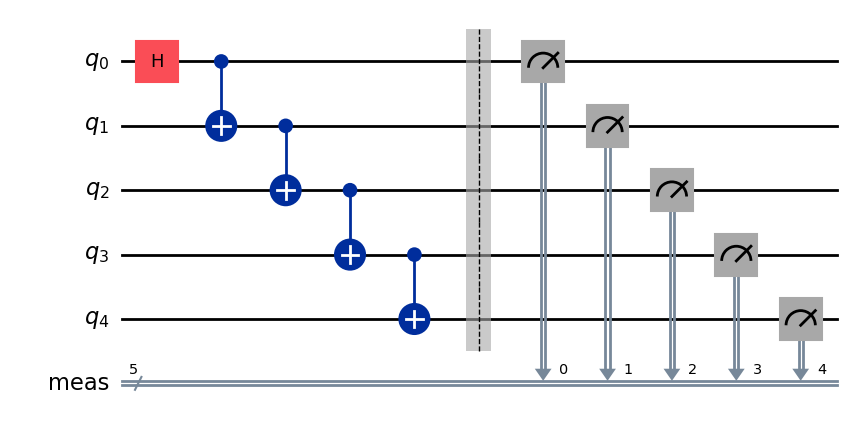

In [2]:
from qiskit import QuantumCircuit

num_qubits = 5
variant = "chain"   # "chain" o "star"

def build_ghz(n: int, variant: str) -> QuantumCircuit:
    """Mismo circuito que en el Notebook 01, para que los resultados sean comparables."""
    qc = QuantumCircuit(n, name=f"GHZ-{n} ({variant})")
    qc.h(0)
    for target in range(1, n):
        control = 0 if variant == "star" else target - 1
        qc.cx(control, target)
    qc.measure_all()
    return qc

circuit = build_ghz(num_qubits, variant)
circuit.draw("mpl", fold=-1)

### Funciones auxiliares

Las mismas utilidades que en la referencia en inglés para normalizar el orden de los bits y calcular la *población GHZ* (probabilidad de medir `00000` o `11111`).

In [3]:
def q0_first(counts: dict) -> dict:
    """Qiskit pone el qubit 0 a la derecha; aquí lo invertimos para ponerlo a la izquierda."""
    return {key.replace(" ", "")[::-1]: value for key, value in counts.items()}


def to_probabilities(counts: dict) -> dict:
    """Convierte conteos a probabilidades, ordenadas de mayor a menor."""
    total = sum(counts.values())
    return {key: value / total for key, value in sorted(counts.items(), key=lambda kv: -kv[1])}


def ghz_population(probs: dict, n: int) -> float:
    """Fracción de disparos que producen el estado GHZ (todos 0 o todos 1)."""
    return probs.get("0" * n, 0.0) + probs.get("1" * n, 0.0)

## IQM Resonance

[IQM Resonance](https://resonance.iqm.tech/) es el acceso cloud a los QPUs superconductores de IQM:
- **Garnet**: 20 qubits, topología de rejilla
- **Emerald**: 54 qubits
- **Sirius**: topología en estrella alrededor de un resonador

El paquete `iqm-client[qiskit]` incluye *fake backends* con la topología y el perfil de error de cada familia de QPU.

### Hardware real de IQM Resonance

Para enviar a hardware real necesitas:
1. Una cuenta en [resonance.iqm.tech](https://resonance.iqm.tech/)
2. Un token API (se muestra solo una vez en el panel)

Pega el token en la variable `IQM_TOKEN` o expórtalo como variable de entorno antes de lanzar Jupyter:
```bash
export IQM_TOKEN="tu_token_aqui"
```

In [5]:
import sys
import os
from getpass import getpass

# Parche de compatibilidad para evitar el error de importación en iqm-client
try:
    import IPython.core.display_functions
except ModuleNotFoundError:
    import types
    import IPython
    # Crear un módulo virtual para satisfacer la dependencia de iqm
    sys.modules['IPython.core.display_functions'] = types.ModuleType('IPython.core.display_functions')
    sys.modules['IPython.core.display_functions'].display = IPython.display.display

from iqm.qiskit_iqm import IQMProvider

IQM_URL = "https://resonance.iqm.tech/"

# Lee el token del entorno o pide al usuario que lo introduzca
iqm_token = os.environ.get("IQM_TOKEN") or getpass("Token IQM Resonance: ")

# QPU disponibles: "garnet", "emerald", "sirius"
iqm_qpu = "emerald"

try:
    iqm_provider = IQMProvider(IQM_URL, quantum_computer=iqm_qpu, token=iqm_token)
    iqm_backend = iqm_provider.get_backend()
    print(f"✅ Conectado a IQM {iqm_qpu} ({iqm_backend.num_qubits} qubits)")
except Exception as e:
    iqm_backend = None
    print(f"❌ No se pudo conectar a Resonance: {e}")

Token IQM Resonance: ··········
✅ Conectado a IQM emerald (54 qubits)


In [6]:
from qiskit import transpile

TRANSPILE_SEED = 7

# Compilar para el QPU real
if iqm_backend is not None:
    compiled_hw = transpile(circuit, backend=iqm_backend, optimization_level=3, seed_transpiler=TRANSPILE_SEED)
    print(f"Puertas compiladas: {compiled_hw.count_ops()}")
    print(f"Profundidad: {compiled_hw.depth()}")
    compiled_hw.draw("mpl", fold=-1, idle_wires=False)
else:
    print("Conéctate primero a Resonance (celda anterior).")

Puertas compiladas: OrderedDict({'r': 9, 'measure': 5, 'cz': 4, 'barrier': 1})
Profundidad: 10


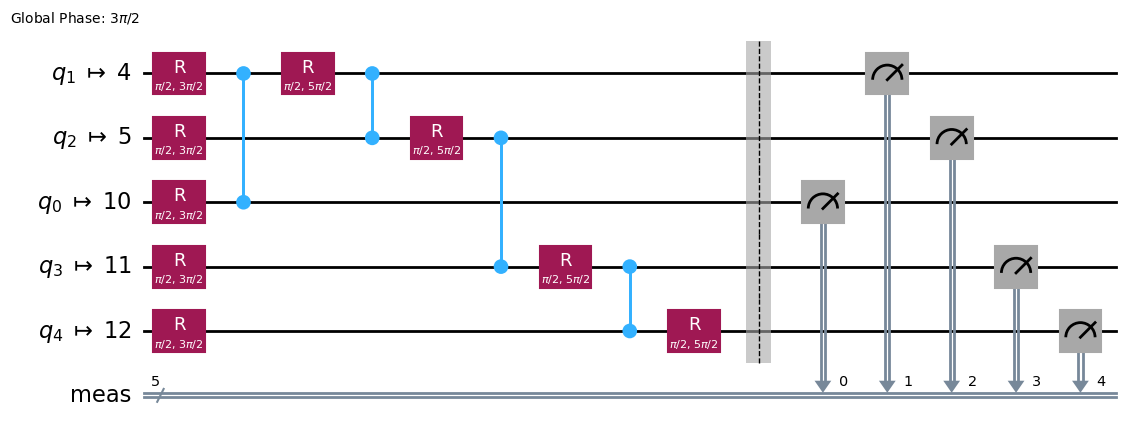

In [11]:
compiled_hw.draw('mpl')

In [7]:
SHOTS = 1000

# ⚠️ Esta celda consume créditos de Resonance. Ejecútala solo cuando estés listo.
iqm_job = None
if iqm_backend is not None:
    iqm_job = iqm_backend.run(compiled_hw, shots=SHOTS)
    print(f"✅ Job enviado. ID: {iqm_job.job_id()}")
    print("Espera a que termine y ejecuta la celda de recogida de resultados.")
else:
    print("Backend IQM no disponible. Omitiendo envío.")

✅ Job enviado. ID: 01a1d3fc-5d64-771e-8e14-0b4301e53bdf
Espera a que termine y ejecuta la celda de recogida de resultados.


Estado del job: DONE
P(GHZ) en emerald: 0.913


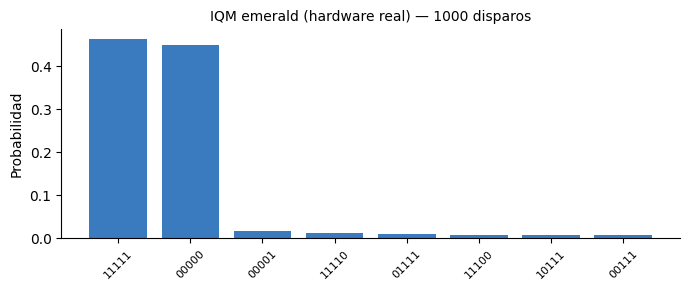

In [8]:
import matplotlib.pyplot as plt

# Recoger resultados (ejecútala cuando el job esté en estado DONE)
probs_iqm_hw = None
if iqm_job is not None:
    status = iqm_job.status().name
    print(f"Estado del job: {status}")
    if status == "DONE":
        counts_iqm_hw = q0_first(iqm_job.result().get_counts())
        probs_iqm_hw = to_probabilities(counts_iqm_hw)
        print(f"P(GHZ) en {iqm_qpu}: {ghz_population(probs_iqm_hw, num_qubits):.3f}")

        top_hw = list(probs_iqm_hw.items())[:8]
        fig, ax = plt.subplots(figsize=(7, 3))
        ax.bar([k for k, _ in top_hw], [p for _, p in top_hw], color="#3a7abf")
        ax.set_ylabel("Probabilidad")
        ax.set_title(f"IQM {iqm_qpu} (hardware real) — {SHOTS} disparos", fontsize=10)
        ax.tick_params(axis="x", rotation=45, labelsize=8)
        ax.spines[["top", "right"]].set_visible(False)
        fig.tight_layout()
        plt.show()
else:
    print("No hay job IQM activo.")

## IonQ

[IonQ](https://ionq.com/) ofrece QPUs basados en **iones atrapados**, con una fidelidad de puerta muy alta y conectividad all-to-all (todos los qubits están conectados entre sí).

El paquete `qiskit-ionq` permite usar la API de IonQ directamente desde Qiskit sin transpilación manual, ya que IonQ acepta circuitos de Qiskit directamente.

Backends disponibles:
- `ionq_simulator`: simulador gratuito (con ruido opcional)
- `ionq_qpu`: hardware real (alias del QPU por defecto)
- `ionq_qpu.aria-1`: Aria 1 (25 qubits)
- `ionq_qpu.forte-1`: Forte 1 (36 qubits)

Consigue tu API key en [cloud.ionq.com](https://cloud.ionq.com).

In [9]:
from qiskit_ionq import IonQProvider

ionq_api_key = os.environ.get("IONQ_API_KEY") or getpass("API Key de IonQ: ")

try:
    ionq_provider = IonQProvider(token=ionq_api_key)
    # Lista todos los backends disponibles
    backends_ionq = ionq_provider.backends()
    print("✅ Conectado a IonQ. Backends disponibles:")
    for b in backends_ionq:
        print(f"  - {b.name}")
except Exception as e:
    ionq_provider = None
    print(f"❌ No se pudo conectar a IonQ: {e}")

API Key de IonQ: ··········
✅ Conectado a IonQ. Backends disponibles:
  - ionq_simulator
  - ionq_qpu


/usr/local/lib/python3.13/dist-packages/qiskit_ionq/ionq_backend.py:129: IonQTranspileLevelWarning: Transpiler default optimization_level=2. IonQ (QIS) recommends 0-1 to avoid aggressive re-synthesis; use transpile(..., optimization_level=1).
  warn_bad_transpile_level()


### Simulador de IonQ

El simulador de IonQ es gratuito y permite verificar el circuito antes de usar el QPU real.

Backend: ionq_simulator
P(GHZ) con simulador IonQ: 1.000


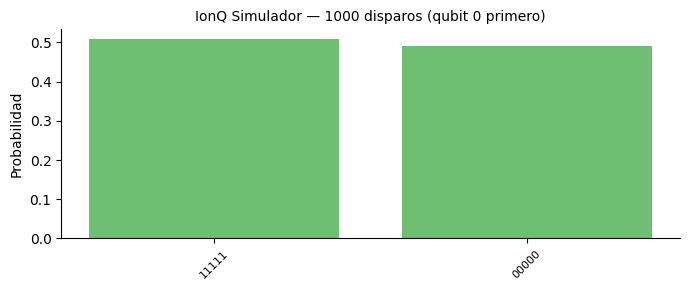

In [10]:
probs_ionq_sim = None
if ionq_provider is not None:
    ionq_sim_backend = ionq_provider.get_backend("ionq_simulator")
    print(f"Backend: {ionq_sim_backend.name}")

    # IonQ acepta circuitos de Qiskit directamente
    job_ionq_sim = ionq_sim_backend.run(circuit, shots=SHOTS)
    result_ionq_sim = job_ionq_sim.result()
    counts_ionq_sim = q0_first(result_ionq_sim.get_counts())
    probs_ionq_sim = to_probabilities(counts_ionq_sim)

    print(f"P(GHZ) con simulador IonQ: {ghz_population(probs_ionq_sim, num_qubits):.3f}")

    top_sim = list(probs_ionq_sim.items())[:8]
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.bar([k for k, _ in top_sim], [p for _, p in top_sim], color="#6fbf73")
    ax.set_ylabel("Probabilidad")
    ax.set_title(f"IonQ Simulador — {SHOTS} disparos (qubit 0 primero)", fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()
else:
    print("Proveedor IonQ no disponible.")